In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in octalpha2r_ko_analysis.py next to this notebook
# (run it as a script to regenerate everything: python octalpha2r_ko_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import octalpha2r_ko_analysis as ana

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = ana.load_session_manager()     # folders: see ana.BASEDIR, ana.DEFAULT_FIGDIR
sess_manager.sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,closed_loop,dark,usable,notes,session,fly_id
0,05_05_2026,fly1,closed_loop-000,0,fictrac-20260505_102519.dat,nocrispr_control,closed_loop,1,0,1,NaN,closed_loop-000,05_05_2026_fly1_condition_nocrispr_control
1,05_05_2026,fly1,dark-001,1,fictrac-20260505_102519.dat,nocrispr_control,dark,0,1,1,NaN,dark-001,05_05_2026_fly1_condition_nocrispr_control
2,05_05_2026,fly2,closed_loop-000,0,fictrac-20260505_115036.dat,nocrispr_control,closed_loop,1,0,1,NaN,closed_loop-000,05_05_2026_fly2_condition_nocrispr_control
3,05_05_2026,fly2,dark-001,1,fictrac-20260505_115036.dat,nocrispr_control,dark,0,1,1,NaN,dark-001,05_05_2026_fly2_condition_nocrispr_control
4,06_05_2026,fly1,closed_loop-000,0,fictrac-20260506_110733.dat,nocrispr_control,closed_loop,1,0,1,NaN,closed_loop-000,06_05_2026_fly1_condition_nocrispr_control


## Offset vector length and variance, dark vs closed loop

offset_var_mixed_anova


,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition,6.994649,1,22,6.994649,13.102922,1.517310e-03,0.373272,NaN
1,dark,32.013608,1,22,32.013608,88.840685,3.502811e-09,0.801517,1.0
2,Interaction,3.742081,1,22,3.742081,10.384618,3.918422e-03,0.320665,NaN


offset_var_pairwise_dark_effect


,Contrast,condition,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,condition,-,ko,nocrispr_control,False,True,3.619796,22.0,two-sided,1.517310e-03,NaN,NaN,21.856,1.426818
1,dark,-,0,1,True,True,-7.943291,23.0,two-sided,4.844924e-08,NaN,NaN,2.95e+05,-1.975966
2,condition * dark,ko,0,1,True,True,-3.755269,11.0,two-sided,3.180685e-03,3.180685e-03,holm,15.173,-1.646641
3,condition * dark,nocrispr_control,0,1,True,True,-11.216705,11.0,two-sided,2.320815e-07,4.641630e-07,holm,6.109e+04,-3.002013


offset_var_pairwise_group_effect


,Contrast,dark,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,hedges
0,dark,-,0,1,True,True,-7.943291,23.0,two-sided,4.844924e-08,NaN,NaN,2.95e+05,-1.975966
1,condition,-,ko,nocrispr_control,False,True,3.619796,22.0,two-sided,1.517310e-03,NaN,NaN,21.856,1.426818
2,dark * condition,0,ko,nocrispr_control,False,True,4.914880,22.0,two-sided,6.475678e-05,0.000130,holm,293.76,1.937302
3,dark * condition,1,ko,nocrispr_control,False,True,0.740419,22.0,two-sided,4.668750e-01,0.466875,holm,0.456,0.291852


offset_n_flies


,condition,n_flies
0,ko,12
1,nocrispr_control,12


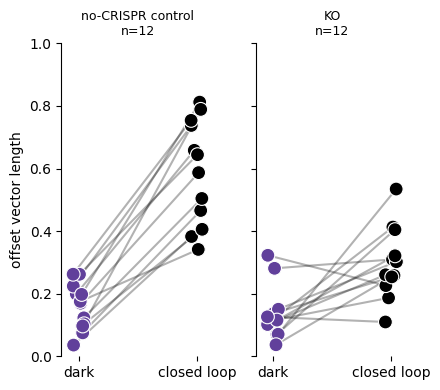

In [3]:
offset_unique, offset_tables = ana.offset_analysis(sess_manager)
for name, table in offset_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## PV magnitude vs rotation speed

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/group_comparison.py:175: RuntimeWarning: Mean of empty slice
  lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()


rho_mean_over_speed_tests


,condition,test,comparison,statistic,p,p_holm
0,closed loop,Mann-Whitney U,no-CRISPR control vs KO,93.0,0.236584,0.236584
1,dark,Mann-Whitney U,no-CRISPR control vs KO,59.0,0.470486,0.470486


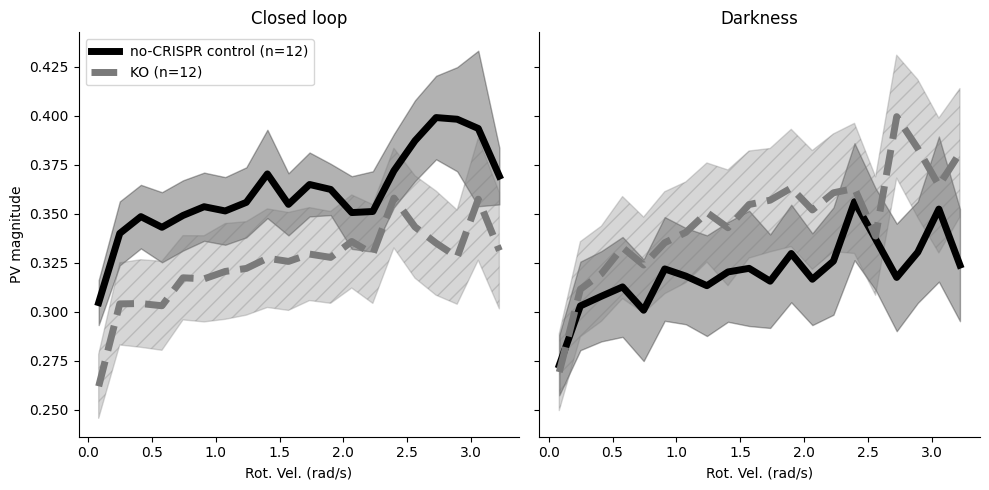

In [4]:
rho_grouped, rho_tables = ana.rho_analysis(sess_manager)
for name, table in rho_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## PVA velocity vs rotation speed

/home/mplitt/repos/plitt_turnerevans_oa_instructs_hd_plasticity/src/el_hd_plasticity/two_photon/group_comparison.py:175: RuntimeWarning: Mean of empty slice
  lambda x: np.nanmean(np.stack(x), axis=0)).reset_index()


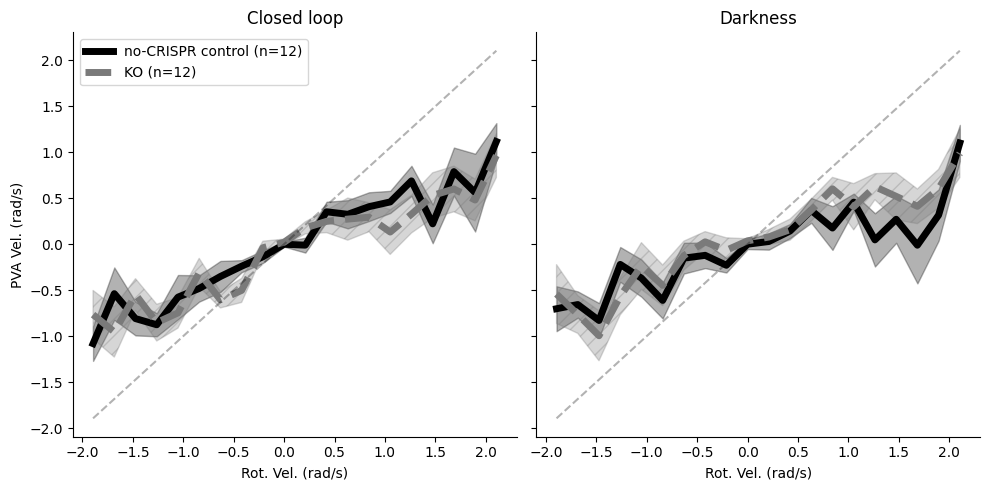

In [5]:
dphi_grouped, dphi_tables = ana.dphi_analysis(sess_manager)
for name, table in dphi_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Bump width

bump_width_tests


,family,comparison,n,W,p,p_holm
0,closed loop vs dark,no-CRISPR control,12.0,6.0,0.006836,0.013672
1,closed loop vs dark,KO,12.0,20.0,0.151367,0.151367
2,"closed loop, between groups",no-CRISPR control vs KO,NaN,32.0,0.022576,0.022576
3,"change (closed loop - dark), between groups",no-CRISPR control vs KO,NaN,33.0,0.026229,0.026229


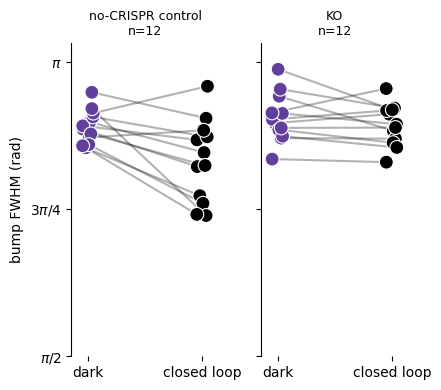

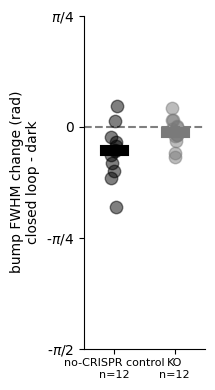

In [8]:
widths, width_tables = ana.width_analysis(sess_manager)
for name, table in width_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

In [10]:
import numpy as np
np.pi/2

1.5707963267948966

## Closed-loop and dark heatmaps of every fly

In [7]:
plotted_flies = ana.plot_session_figures(sess_manager)
len(plotted_flies)

24